In [3]:
import polars as pl
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from pathlib import Path
from procompa import get_project_root

PRJ_ROOT = get_project_root()
data_dir = PRJ_ROOT / "data"

In [4]:
one_model = pl.read_parquet(data_dir/ "Pipeline/18_CP_model_based_on_pae/cf_pdb_structure_similarity/cf_pdb_eval_all_metrics.parquet")

#add confidence
conf_om = {}
for d in {Path(p).parent for p in one_model["combfold_output_path"]}:
    conf_om .update(dict(line.split() for line in open(d / "confidence.txt")))

one_model = one_model.with_columns(pl.col("combfold_output_path").map_elements(lambda p: float(conf_om[p]), return_dtype=pl.Float64).alias("CF_confidence"))
#filter_bigger_proteins
one_model= one_model.filter(pl.col("n_proteins") > 2)
one_model_one_per_complex = one_model.sort("CF_confidence", descending=True).group_by("complex_ac").first()

multiple_input_models = pl.read_parquet(data_dir / "Pipeline/14_CF_multiple_models/cf_pdb_structure_similarity/cf_pdb_eval_all_metrics.parquet")

conf_mm = {}
for d in {Path(p).parent for p in multiple_input_models["combfold_output_path"]}:
    conf_mm .update(dict(line.split() for line in open(d / "confidence.txt")))

multiple_input_models = multiple_input_models.with_columns(pl.col("combfold_output_path").map_elements(lambda p: float(conf_mm[p]), return_dtype=pl.Float64).alias("CF_confidence"))
multiple_input_models = multiple_input_models.filter(pl.col("n_proteins") > 2)
multiple_input_models_one_per_complex  = multiple_input_models.sort("CF_confidence", descending=True).group_by("complex_ac").first()

In [5]:
a = set(one_model_one_per_complex["complex_ac"])
b = set(multiple_input_models_one_per_complex["complex_ac"])

print(f"1-model: {len(a)}   5-model: {len(b)}   shared: {len(a & b)}")
print(f"only in 1-model: {sorted(a - b)}")
print(f"only in 5-model: {sorted(b - a)}")

1-model: 41   5-model: 43   shared: 41
only in 1-model: []
only in 5-model: ['CPX-1040', 'CPX-2156']


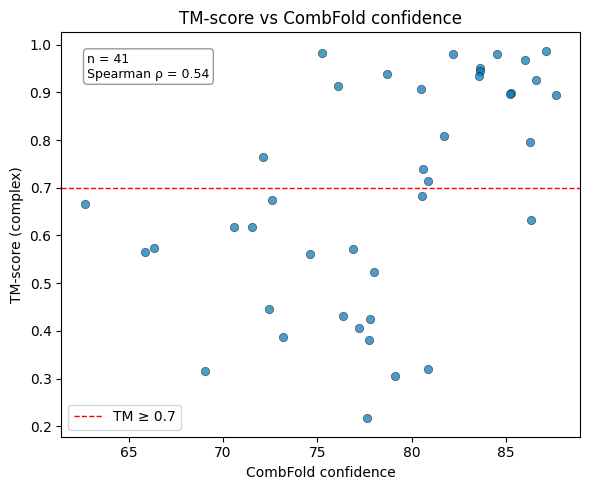

In [6]:

#sanity check
one_model_one_per_complex = one_model.sort("CF_confidence", descending=True).group_by("complex_ac").first()

fig, ax = plt.subplots(figsize=(6, 5))
ax.scatter(
    one_model_one_per_complex["CF_confidence"], one_model_one_per_complex["usalign_cpx_tm_score"],
    alpha=0.7, edgecolors="k", linewidths=0.4, color="#0072B2"
)
ax.axhline(0.7, color="red", linestyle="--", linewidth=1, label="TM ≥ 0.7")
ax.set_xlabel("CombFold confidence")
ax.set_ylabel("TM-score (complex)")
ax.set_title("TM-score vs CombFold confidence")
ax.legend()

x = one_model_one_per_complex["CF_confidence"].to_numpy()
y = one_model_one_per_complex["usalign_cpx_tm_score"].to_numpy()
spearman_r, spearman_p = stats.spearmanr(x, y)

ax.annotate(
    f"n = {len(x)}\nSpearman ρ = {spearman_r:.2f}",
    xy=(0.05, 0.95), xycoords="axes fraction", va="top", fontsize=9,
    bbox=dict(boxstyle="round,pad=0.3", facecolor="white", edgecolor="gray", alpha=0.8)
)
fig.tight_layout()
plt.show()


In [7]:
eval_comparison = (
    one_model_one_per_complex.select("complex_ac", usalign_cpx_tm_score_1model="usalign_cpx_tm_score")
    .join(
        multiple_input_models_one_per_complex.select("complex_ac", usalign_cpx_tm_score_5models="usalign_cpx_tm_score"),
        on="complex_ac",
        how="inner",
    )
)

In [8]:
eval_comparison = (
    one_model_one_per_complex.select(
        "complex_ac",
        usalign_cpx_tm_score_1model="usalign_cpx_tm_score",
        CF_confidence_1model="CF_confidence",
    )
    .join(
        multiple_input_models_one_per_complex.select(
            "complex_ac",
            usalign_cpx_tm_score_5models="usalign_cpx_tm_score",
            CF_confidence_5models="CF_confidence",
        ),
        on="complex_ac",
        how="inner",
    )
    .with_columns(
        (pl.col("usalign_cpx_tm_score_5models") - pl.col("usalign_cpx_tm_score_1model")).alias("delta_tm"),
        (pl.col("CF_confidence_5models") - pl.col("CF_confidence_1model")).alias("delta_conf"),
    )
    .with_columns(
        pl.when(pl.col("delta_tm") > 0.01).then(pl.lit("5models better"))
        .when(pl.col("delta_tm") < -0.01).then(pl.lit("1model better"))
        .otherwise(pl.lit("tied"))
        .alias("winner_tm"),
        pl.when(pl.col("delta_conf") > 0.01).then(pl.lit("5models better"))
        .when(pl.col("delta_conf") < -0.01).then(pl.lit("1model better"))
        .otherwise(pl.lit("tied"))
        .alias("winner_conf"),
    )
    .sort("delta_tm")
)

In [9]:
eval_comparison

complex_ac,usalign_cpx_tm_score_1model,CF_confidence_1model,usalign_cpx_tm_score_5models,CF_confidence_5models,delta_tm,delta_conf,winner_tm,winner_conf
str,f64,f64,f64,f64,f64,f64,str,str
"""CPX-1810""",0.56477,65.8376,0.37447,72.7147,-0.1903,6.8771,"""1model better""","""5models better"""
"""CPX-1890""",0.38757,73.1627,0.23446,75.2238,-0.15311,2.0611,"""1model better""","""5models better"""
"""CPX-1853""",0.57471,66.3394,0.43621,76.4115,-0.1385,10.0721,"""1model better""","""5models better"""
"""CPX-1710""",0.91242,76.1061,0.78655,82.4394,-0.12587,6.3333,"""1model better""","""5models better"""
"""CPX-1638""",0.89827,85.2425,0.77839,86.4226,-0.11988,1.1801,"""1model better""","""5models better"""
…,…,…,…,…,…,…,…,…
"""CPX-2946""",0.6183,70.5598,0.68326,89.0013,0.06496,18.4415,"""5models better""","""5models better"""
"""CPX-1706""",0.40656,77.1824,0.49739,79.5147,0.09083,2.3323,"""5models better""","""5models better"""
"""CPX-1648""",0.618,71.5263,0.71559,80.1388,0.09759,8.6125,"""5models better""","""5models better"""


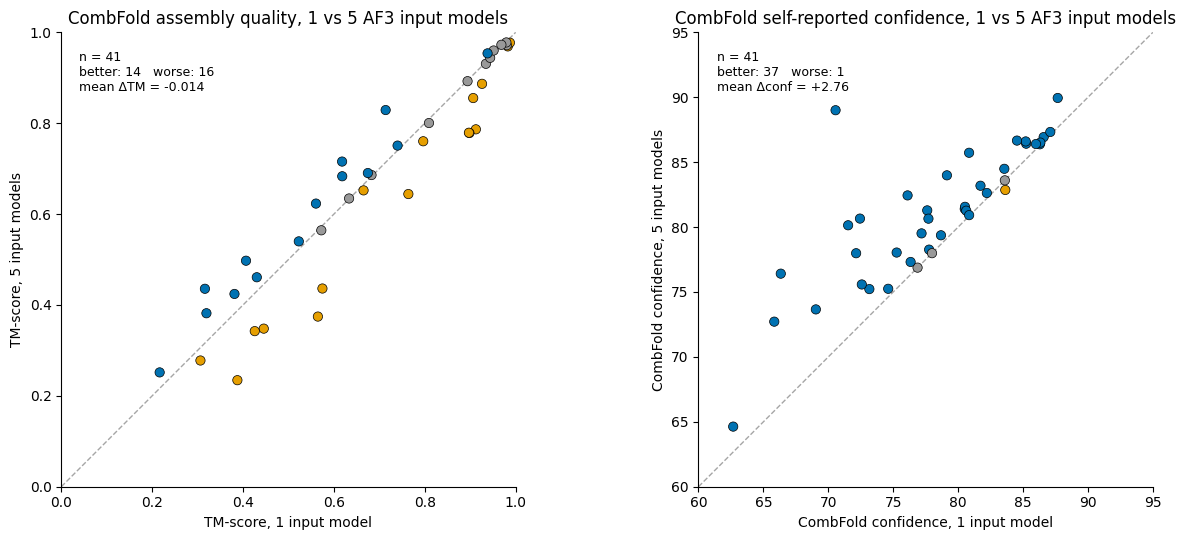

In [15]:
TM_TIE_THRESHOLD = 0.01
CONF_TIE_THRESHOLD = 0.01  

COLOR_FIVE_MODELS_BETTER = "#0072B2"
COLOR_ONE_MODEL_BETTER = "#E69F00"
COLOR_TIED = "#999999"

required_columns = [
    "usalign_cpx_tm_score_1model", "usalign_cpx_tm_score_5models",
    "CF_confidence_1model", "CF_confidence_5models",
    "delta_tm", "delta_conf",
]
assert all(col in eval_comparison.columns for col in required_columns), "missing columns in eval_comparison"
assert eval_comparison.select(required_columns).null_count().sum_horizontal().item() == 0, "nulls in comparison columns"


def plot_paired_comparison(ax, values_1model, values_5models, delta, tie_threshold, axis_limits, delta_label, delta_fmt):
    five_better = delta > tie_threshold
    one_better = delta < -tie_threshold
    point_colors = np.where(five_better, COLOR_FIVE_MODELS_BETTER,
                    np.where(one_better, COLOR_ONE_MODEL_BETTER, COLOR_TIED))

    ax.plot(axis_limits, axis_limits, color="gray", linestyle="--", linewidth=1, alpha=0.7, zorder=0)
    ax.scatter(values_1model, values_5models, c=point_colors, edgecolors="k", linewidths=0.5, s=45, zorder=2)
    ax.set_xlim(axis_limits)
    ax.set_ylim(axis_limits)
    ax.set_aspect("equal")
    ax.spines[["top", "right"]].set_visible(False)

    ax.text(
        0.04, 0.96,
        f"n = {len(delta)}\nbetter: {five_better.sum()}   worse: {one_better.sum()}\n"
        f"mean {delta_label} = {delta.mean():{delta_fmt}}",
        transform=ax.transAxes, va="top", fontsize=9,
    )


tm_1model = eval_comparison["usalign_cpx_tm_score_1model"].to_numpy()
tm_5models = eval_comparison["usalign_cpx_tm_score_5models"].to_numpy()
conf_1model = eval_comparison["CF_confidence_1model"].to_numpy()
conf_5models = eval_comparison["CF_confidence_5models"].to_numpy()

conf_axis_min = np.floor((min(conf_1model.min(), conf_5models.min()) - 1) / 5) * 5
conf_axis_max = np.ceil((max(conf_1model.max(), conf_5models.max()) + 0.5) / 5) * 5

fig, (ax_tm, ax_conf) = plt.subplots(1, 2, figsize=(13, 5.5))

plot_paired_comparison(
    ax_tm, tm_1model, tm_5models, eval_comparison["delta_tm"].to_numpy(),
    TM_TIE_THRESHOLD, (0, 1), "ΔTM", "+.3f",
)
ax_tm.set_xlabel("TM-score, 1 input model")
ax_tm.set_ylabel("TM-score, 5 input models")
ax_tm.set_title("CombFold assembly quality, 1 vs 5 AF3 input models")

plot_paired_comparison(
    ax_conf, conf_1model, conf_5models, eval_comparison["delta_conf"].to_numpy(),
    CONF_TIE_THRESHOLD, (conf_axis_min, conf_axis_max), "Δconf", "+.2f",
)
ax_conf.set_xlabel("CombFold confidence, 1 input model")
ax_conf.set_ylabel("CombFold confidence, 5 input models")
ax_conf.set_title("CombFold self-reported confidence, 1 vs 5 AF3 input models")



fig.tight_layout()
plt.show()